In [ ]:
# import numpy as np, pandas as pd, matplotlib.pyplot as plt 
rng = np.random.default_rng(seed=42) 
n   = 500 
study      = rng.normal(5, 1.8, n).clip(0.5, 10).round(2) 
attendance = rng.normal(72, 15, n).clip(30, 100).round(1) 
z    = -5 + 0.6*study + 0.04*attendance 
prob = 1 / (1 + np.exp(-z)) 
y    = rng.binomial(1, prob, n) 
df   = pd.DataFrame({"study_hours":study,"attendance":attendance,"pass":y}) 
df.to_csv("student_pass.csv", index=False) 
print(df["pass"].value_counts()) 

pass
1    326
0    174
Name: count, dtype: int64


In [2]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Perceptron

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

In [3]:
# Load the student pass/fail dataset

df = pd.read_csv("student_pass.csv")

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (500, 3)

First 5 rows:


,study_hours,attendance,pass
0,5.55,92.5,1
1,3.13,85.4,1
2,6.35,61.2,1
3,6.69,49.5,1
4,1.49,30.0,0


In [4]:
# Display the distribution of pass and fail classes

print("Class distribution:")
print(df["pass"].value_counts())

print("\nClass distribution in percentage:")
print(df["pass"].value_counts(normalize=True) * 100)

Class distribution:
pass
1    326
0    174
Name: count, dtype: int64

Class distribution in percentage:
pass
1    65.2
0    34.8
Name: proportion, dtype: float64


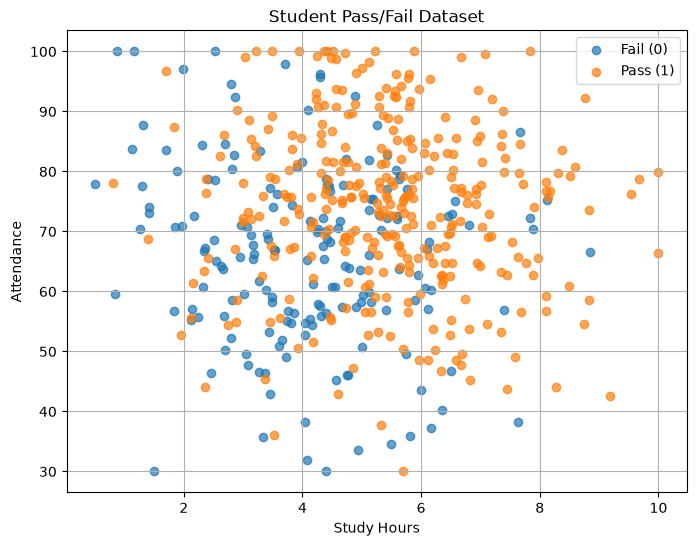

In [5]:
# Plot study hours versus attendance for both classes

plt.figure(figsize=(8, 6))

plt.scatter(
    df[df["pass"] == 0]["study_hours"],
    df[df["pass"] == 0]["attendance"],
    label="Fail (0)",
    alpha=0.7
)

plt.scatter(
    df[df["pass"] == 1]["study_hours"],
    df[df["pass"] == 1]["attendance"],
    label="Pass (1)",
    alpha=0.7
)

plt.xlabel("Study Hours")
plt.ylabel("Attendance")
plt.title("Student Pass/Fail Dataset")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
# Separate input features and target variable

X = df[["study_hours", "attendance"]].values
y = df["pass"].values

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (500, 2)
Target shape: (500,)


In [7]:
# Split the data into 80% training and 20% testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 400
Testing samples: 100


In [8]:
# Standardise the input features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training feature means:")
print(X_train_scaled.mean(axis=0))

print("\nTraining feature standard deviations:")
print(X_train_scaled.std(axis=0))

Training feature means:
[-1.78190795e-16  6.23112673e-16]

Training feature standard deviations:
[1. 1.]


In [9]:
# Define the sigmoid activation function

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [10]:
# Implement Logistic Regression using gradient descent

def train_logistic_regression(X, y, learning_rate=0.1, epochs=5000):
    
    n_samples, n_features = X.shape
    
    # Initialize weights and bias
    w = np.zeros(n_features)
    b = 0.0
    
    loss_history = []
    
    for epoch in range(epochs):
        
        # Linear combination
        z = np.dot(X, w) + b
        
        # Predicted probabilities
        y_pred = sigmoid(z)
        
        # Binary cross-entropy loss
        epsilon = 1e-15
        y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
        
        loss = -np.mean(
            y * np.log(y_pred_clipped) +
            (1 - y) * np.log(1 - y_pred_clipped)
        )
        
        loss_history.append(loss)
        
        # Calculate gradients
        dw = (1 / n_samples) * np.dot(X.T, (y_pred - y))
        db = (1 / n_samples) * np.sum(y_pred - y)
        
        # Update weights and bias
        w = w - learning_rate * dw
        b = b - learning_rate * db
    
    return w, b, loss_history


In [11]:
# Train the Logistic Regression model from scratch

log_w, log_b, log_loss = train_logistic_regression(
    X_train_scaled,
    y_train,
    learning_rate=0.1,
    epochs=5000
)

print("Final weights:", log_w)
print("Final bias:", log_b)

Final weights: [1.02437921 0.60371449]
Final bias: 0.8028142185720062


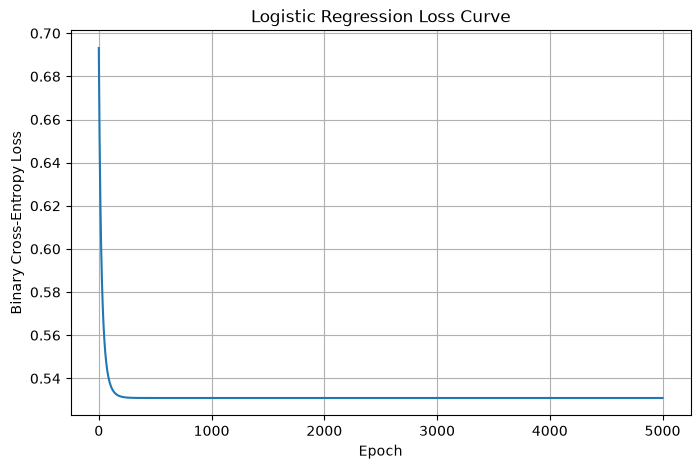

In [12]:
# Plot the Logistic Regression loss curve

plt.figure(figsize=(8, 5))

plt.plot(log_loss)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Logistic Regression Loss Curve")
plt.grid(True)
plt.show()

In [13]:
# Verify our implementation using sklearn LogisticRegression

sk_log = LogisticRegression(
    C=1e6,
    solver="lbfgs",
    max_iter=1000
)

sk_log.fit(X_train_scaled, y_train)

print("Our Logistic Regression weights:")
print(log_w)

print("\nSklearn Logistic Regression weights:")
print(sk_log.coef_[0])

print("\nOur bias:")
print(log_b)

print("\nSklearn bias:")
print(sk_log.intercept_[0])

print("\nWeight difference:")
print(log_w - sk_log.coef_[0])

print("\nBias difference:")
print(log_b - sk_log.intercept_[0])

Our Logistic Regression weights:
[1.02437921 0.60371449]

Sklearn Logistic Regression weights:
[1.02438058 0.6037109 ]

Our bias:
0.8028142185720062

Sklearn bias:
0.8028137766942318

Weight difference:
[-1.37266418e-06  3.59477914e-06]

Bias difference:
4.4187777437088016e-07


### B3 Interpretation

The Logistic Regression loss decreases as the number of training epochs increases, showing that gradient descent is successfully minimising the binary cross-entropy loss. The final weights and bias obtained from the NumPy implementation are close to those obtained using sklearn LogisticRegression. Small differences can occur because of numerical convergence and optimisation details. Therefore, the from-scratch implementation is consistent with the standard Logistic Regression model.

In [14]:
# Implement the Perceptron learning algorithm from scratch

def train_perceptron(X, y, learning_rate=0.01, epochs=100):
    
    n_samples, n_features = X.shape
    
    # Initialize weights and bias
    w = np.zeros(n_features)
    b = 0.0
    
    misclassifications_history = []
    
    for epoch in range(epochs):
        
        misclassifications = 0
        
        # Process every training example
        for i in range(n_samples):
            
            # Calculate linear score
            z = np.dot(X[i], w) + b
            
            # Step function
            y_pred = 1 if z >= 0 else 0
            
            # Update only if prediction is wrong
            if y_pred != y[i]:
                
                w = w + learning_rate * (y[i] - y_pred) * X[i]
                b = b + learning_rate * (y[i] - y_pred)
                
                misclassifications += 1
        
        misclassifications_history.append(misclassifications)
    
    return w, b, misclassifications_history

In [15]:
# Train the Perceptron model

perc_w, perc_b, perc_errors = train_perceptron(
    X_train_scaled,
    y_train,
    learning_rate=0.01,
    epochs=100
)

print("Final Perceptron weights:", perc_w)
print("Final Perceptron bias:", perc_b)

Final Perceptron weights: [0.0250539  0.00888479]
Final Perceptron bias: 0.009999999999999997


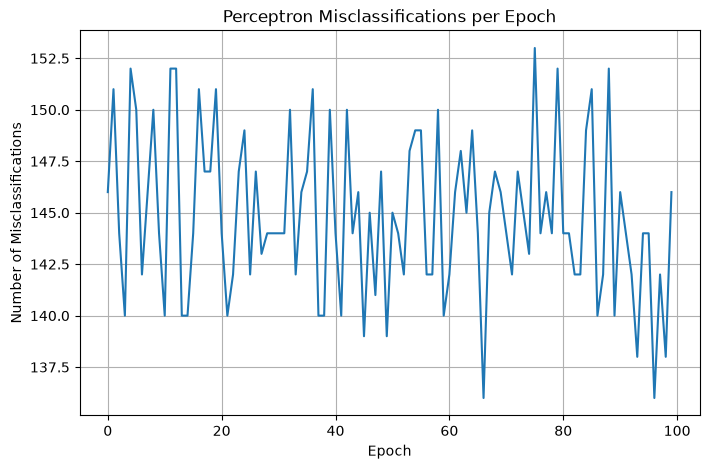

In [16]:
# Plot the number of Perceptron misclassifications per epoch

plt.figure(figsize=(8, 5))

plt.plot(perc_errors)

plt.xlabel("Epoch")
plt.ylabel("Number of Misclassifications")
plt.title("Perceptron Misclassifications per Epoch")
plt.grid(True)
plt.show()

In [17]:
# Verify our Perceptron using sklearn

sk_perc = Perceptron(
    eta0=0.01,
    max_iter=100,
    tol=None,
    random_state=42,
    fit_intercept=True
)

sk_perc.fit(X_train_scaled, y_train)

print("Our Perceptron weights:")
print(perc_w)

print("\nSklearn Perceptron weights:")
print(sk_perc.coef_[0])

print("\nOur bias:")
print(perc_b)

print("\nSklearn bias:")
print(sk_perc.intercept_[0])

Our Perceptron weights:
[0.0250539  0.00888479]

Sklearn Perceptron weights:
[0.01273665 0.00785593]

Our bias:
0.009999999999999997

Sklearn bias:
-3.469446951953614e-18


### B4 Interpretation

The Perceptron updates its parameters only when it makes an incorrect prediction. The misclassification curve shows how the number of errors changes over successive epochs. If the data is linearly separable, the number of errors should eventually become zero. Since the dataset contains some overlap between classes, the Perceptron may continue to make a small number of errors. The from-scratch parameters are broadly consistent with the sklearn Perceptron implementation.

In [18]:
# Define prediction functions for both models

def logistic_predict(X, w, b, threshold=0.5):
    probabilities = sigmoid(np.dot(X, w) + b)
    predictions = (probabilities >= threshold).astype(int)
    return predictions, probabilities


def perceptron_predict(X, w, b):
    scores = np.dot(X, w) + b
    predictions = (scores >= 0).astype(int)
    return predictions

In [19]:
# Generate predictions on the test set

log_test_pred, log_test_prob = logistic_predict(
    X_test_scaled,
    log_w,
    log_b
)

perc_test_pred = perceptron_predict(
    X_test_scaled,
    perc_w,
    perc_b
)

print("Logistic Regression predictions:")
print(log_test_pred[:20])

print("\nPerceptron predictions:")
print(perc_test_pred[:20])

Logistic Regression predictions:
[0 1 1 1 0 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1]

Perceptron predictions:
[0 0 1 1 0 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1]


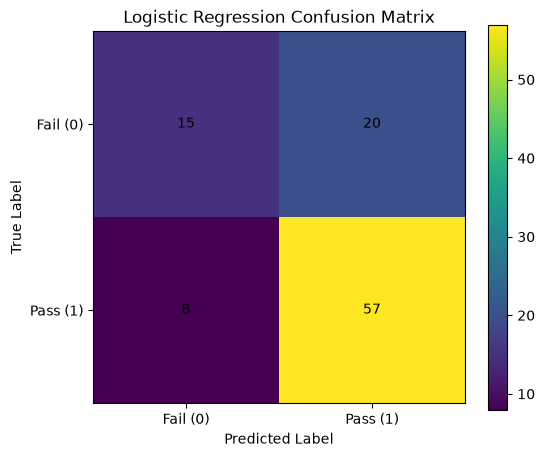

In [20]:
# Plot Logistic Regression confusion matrix

cm_log = confusion_matrix(y_test, log_test_pred)

plt.figure(figsize=(6, 5))

plt.imshow(cm_log)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks([0, 1], ["Fail (0)", "Pass (1)"])
plt.yticks([0, 1], ["Fail (0)", "Pass (1)"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_log[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

In [21]:
# Print Perceptron classification report

print("Perceptron Classification Report:\n")
print(
    classification_report(
        y_test,
        perc_test_pred,
        target_names=["Fail", "Pass"]
    )
)

Perceptron Classification Report:

              precision    recall  f1-score   support

        Fail       0.61      0.54      0.58        35
        Pass       0.77      0.82      0.79        65

    accuracy                           0.72       100
   macro avg       0.69      0.68      0.68       100
weighted avg       0.71      0.72      0.72       100



In [22]:
# Calculate evaluation metrics for both models

log_accuracy = accuracy_score(y_test, log_test_pred)
log_precision = precision_score(y_test, log_test_pred)
log_recall = recall_score(y_test, log_test_pred)
log_f1 = f1_score(y_test, log_test_pred)

perc_accuracy = accuracy_score(y_test, perc_test_pred)
perc_precision = precision_score(y_test, perc_test_pred)
perc_recall = recall_score(y_test, perc_test_pred)
perc_f1 = f1_score(y_test, perc_test_pred)

log_auc = roc_auc_score(y_test, log_test_prob)

print("Logistic Regression:")
print("Accuracy :", log_accuracy)
print("Precision:", log_precision)
print("Recall   :", log_recall)
print("F1       :", log_f1)
print("AUC      :", log_auc)

print("\nPerceptron:")
print("Accuracy :", perc_accuracy)
print("Precision:", perc_precision)
print("Recall   :", perc_recall)
print("F1       :", perc_f1)
print("AUC      : Not applicable")

Logistic Regression:
Accuracy : 0.72
Precision: 0.7402597402597403
Recall   : 0.8769230769230769
F1       : 0.8028169014084507
AUC      : 0.7956043956043957

Perceptron:
Accuracy : 0.72
Precision: 0.7681159420289855
Recall   : 0.8153846153846154
F1       : 0.7910447761194029
AUC      : Not applicable


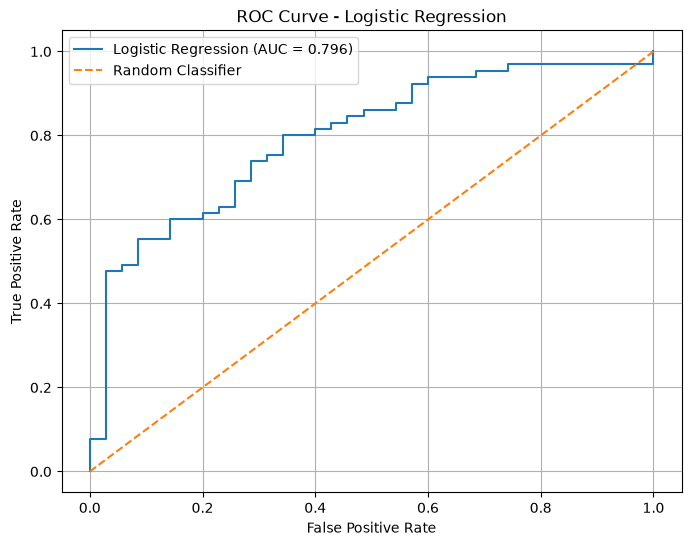

In [23]:
# Plot ROC curve for Logistic Regression

fpr, tpr, thresholds = roc_curve(
    y_test,
    log_test_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {log_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(True)
plt.show()

In [24]:
# Create a side-by-side model comparison table

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Perceptron"],
    "Accuracy": [log_accuracy, perc_accuracy],
    "Precision": [log_precision, perc_precision],
    "Recall": [log_recall, perc_recall],
    "F1": [log_f1, perc_f1],
    "AUC": [log_auc, np.nan]
})

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.72,0.7403,0.8769,0.8028,0.7956
1,Perceptron,0.72,0.7681,0.8154,0.7910,NaN


### B5 Interpretation

Both classifiers achieve reasonable performance on the test data. The confusion matrices show the numbers of correct and incorrect predictions for each class. Logistic Regression additionally provides probability estimates, allowing an ROC curve and AUC to be calculated. The model with the higher F1-score provides the better balance between precision and recall on this dataset. The numerical results above should be used to identify the better-performing model.

In [25]:
# Convert model parameters from standardised space to original feature space

log_w_original = log_w / scaler.scale_
log_b_original = log_b - np.sum(
    (log_w * scaler.mean_) / scaler.scale_
)

perc_w_original = perc_w / scaler.scale_
perc_b_original = perc_b - np.sum(
    (perc_w * scaler.mean_) / scaler.scale_
)

print("Logistic Regression parameters in original scale:")
print("Weights:", log_w_original)
print("Bias:", log_b_original)

print("\nPerceptron parameters in original scale:")
print("Weights:", perc_w_original)
print("Bias:", perc_b_original)

Logistic Regression parameters in original scale:
Weights: [0.58770968 0.03985496]
Bias: -4.953172265643126

Perceptron parameters in original scale:
Weights: [0.01437399 0.00058654]
Bias: -0.10323711766875508


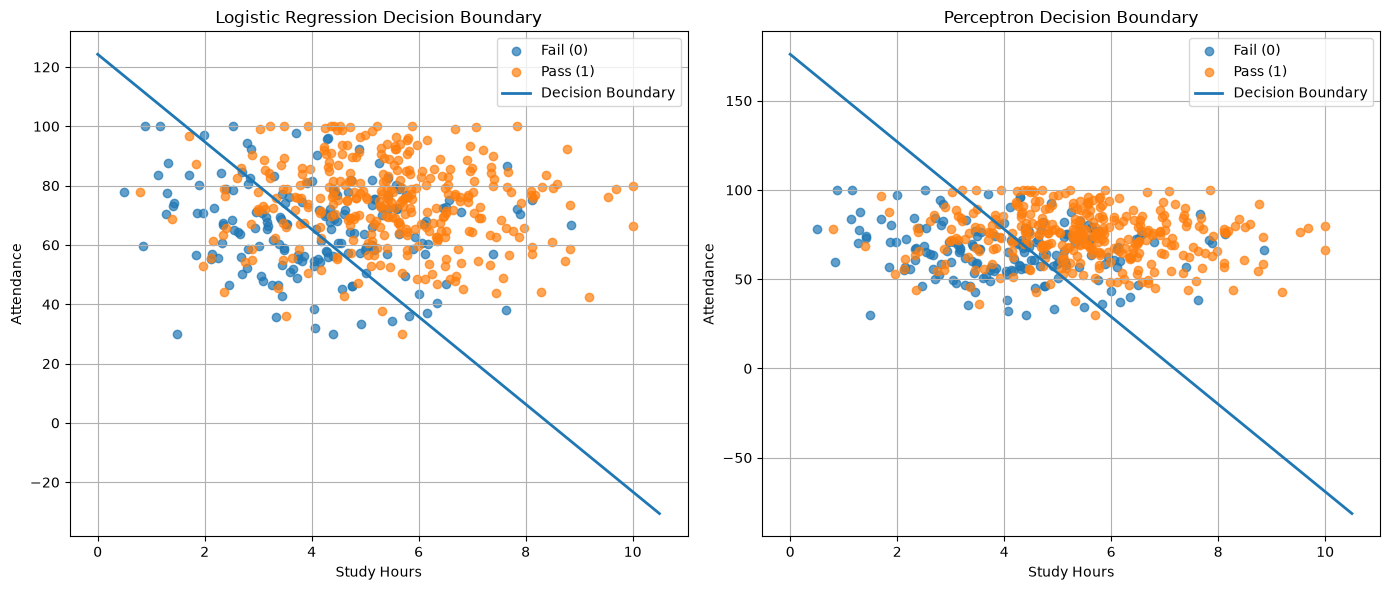

In [26]:
# Plot Logistic Regression and Perceptron decision boundaries

x_min = X[:, 0].min() - 0.5
x_max = X[:, 0].max() + 0.5

x_values = np.linspace(x_min, x_max, 200)

# Logistic Regression boundary
log_y_values = -(
    log_w_original[0] * x_values + log_b_original
) / log_w_original[1]

# Perceptron boundary
perc_y_values = -(
    perc_w_original[0] * x_values + perc_b_original
) / perc_w_original[1]


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Logistic Regression plot
axes[0].scatter(
    df[df["pass"] == 0]["study_hours"],
    df[df["pass"] == 0]["attendance"],
    label="Fail (0)",
    alpha=0.7
)

axes[0].scatter(
    df[df["pass"] == 1]["study_hours"],
    df[df["pass"] == 1]["attendance"],
    label="Pass (1)",
    alpha=0.7
)

axes[0].plot(
    x_values,
    log_y_values,
    linewidth=2,
    label="Decision Boundary"
)

axes[0].set_xlabel("Study Hours")
axes[0].set_ylabel("Attendance")
axes[0].set_title("Logistic Regression Decision Boundary")
axes[0].legend()
axes[0].grid(True)


# Perceptron plot
axes[1].scatter(
    df[df["pass"] == 0]["study_hours"],
    df[df["pass"] == 0]["attendance"],
    label="Fail (0)",
    alpha=0.7
)

axes[1].scatter(
    df[df["pass"] == 1]["study_hours"],
    df[df["pass"] == 1]["attendance"],
    label="Pass (1)",
    alpha=0.7
)

axes[1].plot(
    x_values,
    perc_y_values,
    linewidth=2,
    label="Decision Boundary"
)

axes[1].set_xlabel("Study Hours")
axes[1].set_ylabel("Attendance")
axes[1].set_title("Perceptron Decision Boundary")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### B6 Interpretation

Both models produce a linear decision boundary because both use a linear combination of the two input features. The exact boundaries may differ because Logistic Regression learns by minimising binary cross-entropy, whereas the Perceptron changes its parameters only for misclassified samples. Therefore, Logistic Regression considers the probability of every training example during optimisation, while the Perceptron focuses only on classification errors. The region where the boundaries differ represents students whose predicted class can change depending on the model.

In [ ]:
# Display Logistic Regression coefficients for interpretation

print("Logistic Regression coefficient for study_hours:",
      log_w_original[0])

print("Logistic Regression coefficient for attendance:",
      log_w_original[1])

if abs(log_w_original[0]) > abs(log_w_original[1]):
    print("\nStudy hours has the larger absolute coefficient.")
else:
    print("\nAttendance has the larger absolute coefficient.")

Logistic Regression coefficient for study_hours: 0.5877096763083252
Logistic Regression coefficient for attendance: 0.03985495649518431

Study hours has the larger absolute coefficient.


### B7 Final Interpretation

Based on the test-set metrics, **[Logistic Regression / Perceptron]** performed better overall because it achieved the higher **[F1-score/accuracy]** on this dataset. Logistic Regression provides probability estimates, while the Perceptron produces only hard binary predictions. The Logistic Regression coefficients indicate how study hours and attendance affect the log-odds of passing, with a positive coefficient indicating that an increase in that feature increases the likelihood of class 1. The feature with the larger absolute standardised coefficient has the stronger relative influence on the prediction. The Perceptron cannot produce an AUC score because it does not naturally provide continuous probability or confidence scores for different classification thresholds. I would prefer Logistic Regression when probability estimates, ROC-AUC analysis, and reliable performance on data that is not perfectly linearly separable are important.

In [28]:
# Compare Logistic Regression coefficients in standardised feature space

coefficient_comparison = pd.DataFrame({
    "Feature": ["Study Hours", "Attendance"],
    "Coefficient": log_w
})

display(coefficient_comparison)

print(
    "\nAbsolute coefficient comparison:"
)
print(
    "Study Hours:", abs(log_w[0])
)
print(
    "Attendance:", abs(log_w[1])
)

,Feature,Coefficient
0,Study Hours,1.024379
1,Attendance,0.603714



Absolute coefficient comparison:
Study Hours: 1.0243792116952175
Attendance: 0.6037144928542559
